# Which image half does a digit classifier rely on?

| | |
| --- | --- |
| **Question** | When one of two processing pathways in a trained digit classifier is silenced, how much does test accuracy fall, and does the answer differ between the pathway that sees the upper half of the image and the one that sees the lower half? |
| **Requires** | CPU only. Uses the handwritten digit images bundled with scikit-learn (no download). About 10 seconds. |
| **Lessons used** | [1. Your first subject](../lessons/01_your_first_subject.ipynb), [7. Perturb a model](../lessons/07_perturb_a_model.ipynb), [10. Run an experiment](../lessons/10_run_an_experiment.ipynb) |

## Background

Lesion studies infer what a brain area contributes by removing it and measuring the change in behavior. The same logic applies to a trained network: silencing a component and measuring the change in its outputs shows how much the network depends on it.

A useful lesion study needs three controls. The lesion must affect only the intended component. The same inputs must be shown in every condition. The intact behavior must return once the lesion is removed, so that the comparison is not confounded by a lasting change to the model.

## Hypothesis

Both halves of a digit carry information about its identity, so we do not predict which pathway matters more. We predict that silencing either pathway lowers held-out accuracy well below the intact model, that the drop differs between digits, and that accuracy returns exactly to its intact value after the lesion is removed.

## Method

Each 8 by 8 digit image is split into its upper four rows and its lower four rows. A small network processes each half in a separate pathway of 32 units, and a final layer combines the two pathways into a digit prediction. The network is trained on 80% of the images. The other 20% are held out and shown in four conditions: intact, upper pathway silenced, lower pathway silenced, and restored after the lesions are removed.

Silencing sets a pathway's output to zero. It does not change the image or the weights.

## Setup

Imports and settings.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

%matplotlib inline
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 7                                  # one seed for the split and the training
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## The subject

The subject is a two-pathway network trained on the digits, wrapped so that it receives a batch of images on the `vision:image` channel and returns digit probabilities on the `behavior` channel. Lesson 1 explains subjects, channels and `participate`.

First the images are split. The split is stratified so that every digit is equally represented in the training set and in the held-out set, which becomes the stimuli.

In [2]:
digits = load_digits()
images = (digits.images / 16.0).astype(np.float32)      # pixel values 0..16 -> 0..1
labels = digits.target
train_ids, test_ids = train_test_split(
    np.arange(len(images)), test_size=0.2, random_state=SEED, stratify=labels,
)
X_train = torch.from_numpy(images[train_ids])
y_train = torch.tensor(labels[train_ids], dtype=torch.long)
print(f'{len(train_ids)} training images; {len(test_ids)} held-out images.')

1437 training images; 360 held-out images.


The network and its training. Training runs on the CPU with a fixed seed.

In [3]:
class TwoPathDigitModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.upper = torch.nn.Sequential(torch.nn.Linear(32, 32), torch.nn.ReLU())
        self.lower = torch.nn.Sequential(torch.nn.Linear(32, 32), torch.nn.ReLU())
        self.readout = torch.nn.Linear(64, 10)

    def forward(self, pixels):
        # Rows 0-3 go to the upper pathway, rows 4-7 to the lower; each half is 4 x 8 = 32 pixels.
        upper = self.upper(pixels[:, :4, :].reshape(-1, 32))
        lower = self.lower(pixels[:, 4:, :].reshape(-1, 32))
        return self.readout(torch.cat([upper, lower], dim=1))


torch.manual_seed(SEED)
model = TwoPathDigitModel()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
for epoch in range(250):                  # full-batch training: all images in every step
    optimizer.zero_grad()
    loss = torch.nn.functional.cross_entropy(model(X_train), y_train)
    loss.backward()
    optimizer.step()
model.eval()
print(f'Final training loss: {loss.item():.4f}')

Final training loss: 0.0073


In [4]:
from brainscore_core.model_interface import Subject
from brainscore_core.streaming import StreamEvent
from brainscore_core.supported_data_standards.brainio.assemblies import BehavioralAssembly


class DigitSubject(Subject):
    identifier = 'two-path-digits'
    in_channels = {'vision:image'}
    out_channels = {'behavior'}

    def __init__(self, network):
        self.network = network

    def reset(self):
        pass  # the network keeps no state between inputs

    def participate(self, session):
        while (event := session.next_input()) is not None:
            with torch.inference_mode():
                # The image arrives as 8 x 8 x 3 uint8 (gray copied to 3 channels, pixel values 0..16).
                pixels = torch.from_numpy(event.payload[:, :, 0].astype(np.float32) / 16.0)[None]
                logits = self.network(pixels)
            probabilities = logits.softmax(dim=1).numpy()
            responses = BehavioralAssembly(
                probabilities,
                dims=['presentation', 'choice'],
                coords={
                    'stimulus_id': ('presentation', [event.meta['stimulus_id']]),
                    'stimulus_index': ('presentation', np.arange(len(probabilities))),
                    'choice': ('choice', np.arange(10)),
                },
            )
            session.respond(StreamEvent(channel='behavior', payload=responses, t_ms=event.t_ms))


subject = DigitSubject(model)

## The experiment

### Stimuli

The 360 held-out images. One example of each digit is shown; the pink line marks the boundary between the two halves.

In [5]:
X_test = images[test_ids].copy()
y_test = labels[test_ids].copy()

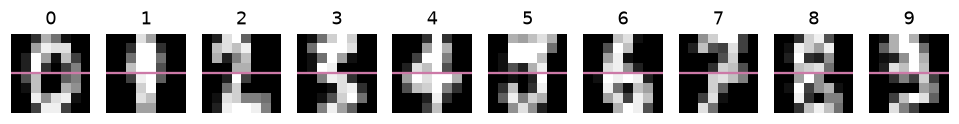

In [6]:
fig, axes = plt.subplots(1, 10, figsize=(11, 1.8))
for digit, ax in enumerate(axes):
    ax.imshow(X_test[np.flatnonzero(y_test == digit)[0]], cmap='gray', vmin=0, vmax=1)
    ax.axhline(3.5, color='#CC79A7', linewidth=1.5)     # between row 3 and row 4
    ax.set_title(str(digit))
    ax.axis('off')
plt.show()

### Task

Plain viewing with an answer: the whole held-out set arrives as one input event, and the subject returns the probability of each digit for every image. Every session receives an identical copy of the images.

In [ ]:
from brainscore_core.streaming import Session


@contextmanager
def make_session(trial):
    # One event per held-out image: 8 x 8 x 3 uint8, the gray level copied to 3 channels.
    events = [StreamEvent(channel='vision:image', t_ms=0, payload=np.repeat(
                  np.rint(image * 16).astype(np.uint8)[:, :, None], 3, axis=2),
                  meta={'stimulus_id': int(image_id)})
              for image, image_id in zip(X_test, test_ids)]
    yield Session(events, requested_output_channels=['behavior'])

### Conditions

Four conditions. Each `Ablate` tool silences one pathway in one condition only; `restored` comes after both lesions have been removed. `RecordActivity` records both pathways after any lesion is applied, which lets us check that each lesion affected only its target. Lesson 10 explains protocols, conditions and tools.

In [8]:
from brainscore.experiments import SessionProtocol, RecordInputsOutputs, RecordActivity, Ablate

CONDITIONS = ['intact', 'upper_silenced', 'lower_silenced', 'restored']

protocol = SessionProtocol(
    identifier='held-out-digits',
    session_factory=make_session,
    conditions=CONDITIONS,
    input_channels=['vision:image'],
    output_channels=['behavior'],
)
tools = [
    RecordInputsOutputs(),
    Ablate(['upper'], conditions=['upper_silenced'], name='silence_upper'),
    Ablate(['lower'], conditions=['lower_silenced'], name='silence_lower'),
    RecordActivity(['upper', 'lower'], when='after'),       # recorded after the lesion
]

## Run

In [9]:
from brainscore.experiments import Experiment, TorchInstrumentation

experiment = Experiment(
    subject=subject,
    protocol=protocol,
    tools=tools,
    instrumentation=TorchInstrumentation(model),     # lets the tools reach the pathways
    metadata={'training_seed': SEED, 'training_epochs': 250,
              'dataset': 'sklearn.load_digits'},
)
result = experiment.run()
print('Run status:', result.manifest['status'])

Run status: complete


## Read results back

The predictions and activity are read back from the saved record. This does not call the model again.

In [10]:
probabilities, activity, shown_ids = {}, {}, {}
for event in result.record.events():
    if event['kind'] == 'output':
        assembly = event['payload'].payload
        probabilities.setdefault(event['condition'], []).append(np.asarray(assembly))
        shown_ids.setdefault(event['condition'], []).extend(assembly['stimulus_id'].values)
    elif event['kind'] == 'activity':
        activity.setdefault((event['condition'], event['payload']['target']), []).append(
            event['payload']['value']['array'])
probabilities = {c: np.concatenate(v) for c, v in probabilities.items()}   # one row per image
activity = {k: np.concatenate(v) for k, v in activity.items()}
assert all(np.array_equal(ids, test_ids) for ids in shown_ids.values())    # same images, same order
sorted(probabilities), sorted(activity)

(['intact', 'lower_silenced', 'restored', 'upper_silenced'],
 [('intact', 'lower'),
  ('intact', 'upper'),
  ('lower_silenced', 'lower'),
  ('lower_silenced', 'upper'),
  ('restored', 'lower'),
  ('restored', 'upper'),
  ('upper_silenced', 'lower'),
  ('upper_silenced', 'upper')])

## Analysis

In [11]:
def predicted_digits(probability_values):
    """The most probable digit for each image."""
    return probability_values.argmax(axis=1)

def percent_correct(predicted, truth):
    """Percentage of images whose predicted digit is the true one."""
    return 100 * np.mean(predicted == truth)

def percent_correct_per_digit(predicted, truth):
    """Percentage correct among the images of each digit, 0 to 9."""
    return [100 * np.mean(predicted[truth == digit] == digit) for digit in range(10)]

## Results

First, the controls: each lesion silenced only its target pathway, and the restored condition matches the intact one.

In [12]:
assert np.count_nonzero(activity['upper_silenced', 'upper']) == 0
assert np.count_nonzero(activity['lower_silenced', 'lower']) == 0
np.testing.assert_array_equal(activity['intact', 'lower'], activity['upper_silenced', 'lower'])
np.testing.assert_array_equal(activity['intact', 'upper'], activity['lower_silenced', 'upper'])
np.testing.assert_array_equal(probabilities['intact'], probabilities['restored'])
print('Each lesion silenced only its target; restored outputs equal intact outputs exactly.')

Each lesion silenced only its target; restored outputs equal intact outputs exactly.


Overall held-out accuracy in each condition.

In [13]:
predicted = {c: predicted_digits(probabilities[c]) for c in CONDITIONS}
accuracy = {c: percent_correct(predicted[c], y_test) for c in CONDITIONS}
pd.DataFrame({'condition': CONDITIONS,
              'held-out accuracy (%)': [round(accuracy[c], 1) for c in CONDITIONS]})

,condition,held-out accuracy (%)
0,intact,97.8
1,upper_silenced,41.9
2,lower_silenced,23.6
3,restored,97.8


Accuracy for each digit in the intact model and after each lesion.

In [14]:
COLORS = {'intact': '#0072B2', 'upper_silenced': '#D55E00', 'lower_silenced': '#009E73'}
per_digit = {c: percent_correct_per_digit(predicted[c], y_test) for c in COLORS}
pd.DataFrame(per_digit, index=pd.Index(range(10), name='digit')).round(1)

,intact,upper_silenced,lower_silenced
digit,,,
0,100.0,2.8,0.0
1,100.0,24.3,2.7
2,94.3,97.1,0.0
3,100.0,75.7,8.1
4,100.0,97.2,0.0
5,97.2,22.2,88.9
6,97.2,100.0,0.0
7,100.0,0.0,36.1
8,97.1,0.0,0.0


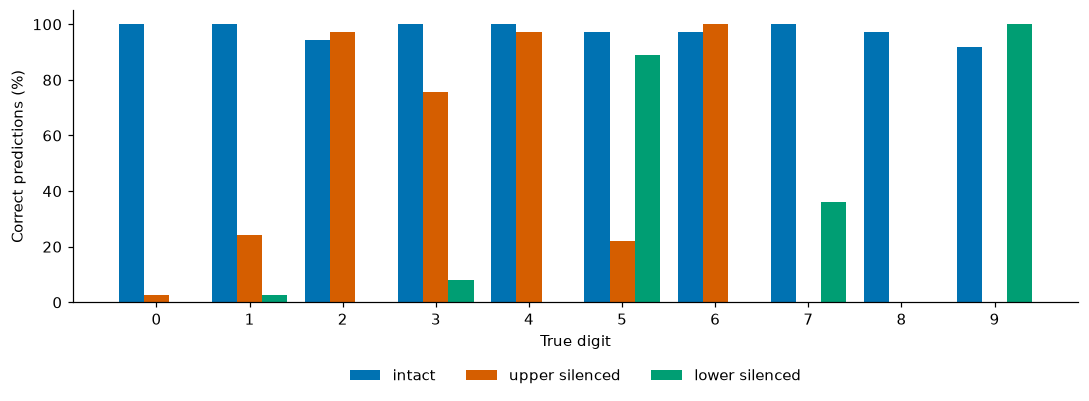

In [15]:
x = np.arange(10)
fig, ax = plt.subplots(figsize=(10, 3.8))
for offset, condition in zip([-0.27, 0, 0.27], COLORS):        # three bars side by side per digit
    ax.bar(x + offset, per_digit[condition], width=0.27, color=COLORS[condition],
           label=condition.replace('_', ' '))
ax.set_xticks(x)
ax.set_xlabel('True digit')
ax.set_ylabel('Correct predictions (%)')
ax.set_ylim(0, 105)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

Held-out accuracy falls from 97.8% intact to 41.9% with the upper pathway silenced and to 23.6% with the lower pathway silenced, and returns to 97.8% after restoration. The effect depends strongly on the digit. Without the upper pathway, digits 7, 8 and 9 are never classified correctly while 2, 4 and 6 stay above 97%. Without the lower pathway, 9 stays at 100% and 5 at 88.9% while seven digits fall to 0%.

## Conclusion and limits

Silencing either pathway lowers held-out accuracy, and the size of the drop depends on the digit. Removing the lesions restores the intact predictions exactly, and each lesion left the other pathway's activity unchanged, so the accuracy differences are caused by the lesions themselves.

The result comes from one small network, one training seed and one train/test split. A different seed could shift the balance between the pathways, so a claim about which image half matters more would need several seeds and a confidence interval. The network is not a model of any brain area, and this experiment makes no claim about biological digit recognition.

To repeat the run from its saved inputs, see the replay section of the [experiments guide](../../docs/guides/experiments.md#read-and-replay).

Back to the [notebook index](../README.md) and the [documentation](../../docs/README.md).